#### Opgaver i eksperimenter

#### Opgave 1 - Beregning af inertimoment
Inertimomentet af et legeme for rotation er analogt til massen af et legeme for rotation. Det bliver behandlet senere i kurset.
Inertimoment betegnes med $I$ og dimensionen af inertimoment er $[I]=\text{ML}^2$.

Inertimomentet, $I$, for en hul cylinder afhænger af dens masse $m$, dens ydre radius $r_1$ og dens indre radius $r_2$, dvs.
$$I=f\left(m,r_1,r_2\right)$$


Data for 20 forskellige hule cylindre beregnes nedenfor, værdierne ligger i *numpy* arrays 
med navnene *m_values*, *r1_values*, *2_values* og *I_values*.
Data har tilføjet støj.

Bestem en model for inertimomentberegningen.

In [21]:
import numpy as np
rnd = np.random.default_rng(67347683476837638476843)
N = 20
m_values = rnd.uniform(low=0.050,high=1.50,size=N)
r2_values = rnd.uniform(low=0.020,high=0.20,size=N)
r1_values = r2_values + rnd.uniform(low=0.020,high=0.20,size=N)
I_values = 1/2 * m_values * (r1_values**2+r2_values**2)
I_values = I_values + rnd.normal(loc=0.0,scale=0.02*I_values,size=N)

Modellen vi undersøger har formen
$$I=f(m,r_1,r_2)$$
Vi ser at kun massedimension og længdedimension er til stede. 
Vi skal altså finde en naturlig masseskala, $\mu$ og en naturlig længdeskala, $\lambda$.
Ved at kigge på de uafhængige variable finder vi
$$\mu=m$$
$$\lambda=r_1$$
De kan nu bruger til at ikke-dimensionslisere vores model
$$\frac{I}{\mu\lambda^2}=f\left(\frac{m}{\mu},\frac{r_1}{\lambda},\frac{r_2}{\lambda}\right)$$
Indsættelse af vores valgte naturlige skalaer giver
$$\frac{I}{mr_1^2}=f\left(\frac{m}{m},\frac{r_1}{r_1},\frac{r_2}{r_1}\right)$$
$$\frac{I}{mr_1^2}=f\left(1,1,\frac{r_2}{r_1}\right)$$
De to $1$'er er ikke reelle parametre, så vi kan reducere modellen til
$$\frac{I}{mr_1^2}=f\left(\frac{r_2}{r_1}\right)$$
Den endelige model har de dimensionsløse parametre $\pi_2=\frac{r_2}{r_1}$ (uafhængig) og $\pi_1=\frac{I}{mr_1^2}$ (afhængig).


Vi beregner de dimensionsløse parametres værdi, $\pi_2=\frac{r_2}{r_1}$ og $\pi_1=\frac{I}{mr_1^2}$.

In [22]:
pi_2 = r2_values/r1_values
pi_1 = I_values/(m_values*r1_values**2)

Så plotter vi vores nu dimensionsløse data.

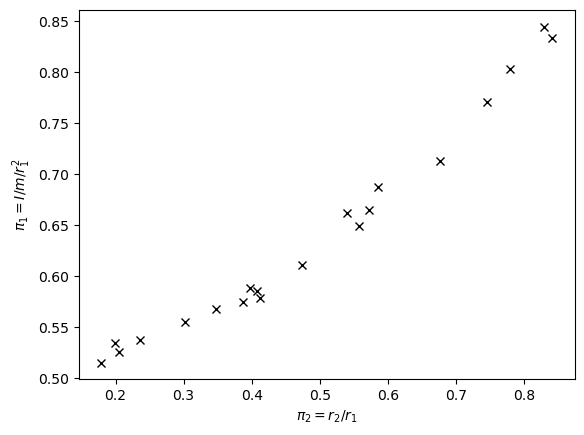

In [23]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(pi_2,pi_1,'kx')
plt.xlabel('$\pi_2=r_2/r_1$')
plt.ylabel('$\pi_1=I/m/r_1^2$')
plt.show()

Vi ser at vi har noget der ligner en voksende funktion der vokser kraftigere med større $\pi_2$.
En simpel model ville være et andengradspolynomium, $f\left(pi_2\right)=A+B\pi_2+C\pi_2^2$.
Vi foretager en regressionanalyse med metode *curve_fit* og bestemmer
værdier og usikkerheder på modellens parametre.

In [24]:
from scipy.optimize import curve_fit
def fun(t,A,B,C):
    return A+B*t+C*t**2
param,cov = curve_fit(fun,pi_2,pi_1)
print(param)
print(np.sqrt(np.diag(cov)))
import uncertainties as unc
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
C = unc.ufloat(param[2],np.sqrt(np.diag(cov))[2])
print(A,B,C)
print(A.std_score(0.5))
print(B.std_score(0.0))
print(C.std_score(0.5))

[0.5049204  0.01507042 0.46073814]
[0.01155243 0.05031526 0.04864733]
0.505+/-0.012 0.02+/-0.05 0.46+/-0.05
-0.42591892403434367
-0.2995199343421918
0.8070712722684972


Vi har ovenfor ud fra værdier og usikkerheder gættet på at modellens parameterværdier kunne være $A=\frac{1}{2}$, $B=0$ og $C=\frac{1}{2}$.
Standardscorerne understøtter dette ved alle at være mindre end én.
$$\pi_1=f(\pi_2)$$
Indsættelse af parameterværdier giver
$$\pi_1=\frac{1}{2}\left(1+\pi_2^2\right)$$
og indsættelse af de fysiske parametre giver
$$\frac{I}{mr_1^2}=\frac{1}{2}\left(1+\left(\frac{r_2}{r_1}\right)^2\right)$$
isolering af den afhængige variabel leder til 
$$I=mr_1^2\frac{1}{2}\left(1+\left(\frac{r_2}{r_1}\right)^2\right)$$
Den endelig model bliver
$$I=\frac{1}{2}m\left(r_1^2+r_2^2\right)$$

####  Opgave 2 - Kinematik

Vi betragter den fysiske situation hvor et legeme til tiden, $t=0$, har starthastigheden $v_0$. Efter et tidsrum, $t$, med den konstante acceleration, $a$, har legemet sluthastigheden, $v$.

Vi ønsker at undersøge hvordan starthastigheden afhænger af accelerationen, tiden og sluthastigheden, dvs. modellen vi forsøger at finde er

>$v_0 = f(a,t,v)$

Undersøg modellen med data givet længere nede. 

Koden nedenfor genererer data, spring det over.

In [25]:
# Disse kommandoer og det tilhørende output er ikke en del af løsningen.
import numpy as np
t = 1.0 + np.random.normal(loc=0,scale=1.0,size=6)
a = np.random.normal(loc=0,scale=1.0,size=6)
v0 = 1.0 + np.random.normal(loc=0,scale=2.0,size=6)
v = v0 + a * t + np.random.normal(loc=0,scale=0.1,size=6)
s = '['
for T in t:
    s = s+ '{:5.3f},'.format(T)
s = s + ']'
print(s)
s = '['
for T in a:
    s = s+ '{:5.3f},'.format(T)
s = s + ']'
print(s)
s = '['
for T in v0:
    s = s+ '{:5.3f},'.format(T)
s = s + ']'
print(s)
s = '['
for T in v:
    s = s+ '{:5.3f},'.format(T)
s = s + ']'
print(s)

[-0.008,0.055,2.880,2.052,0.776,-0.481,]
[0.589,0.167,0.938,0.494,1.163,-0.684,]
[4.109,0.157,3.238,3.345,1.336,-2.820,]
[4.123,0.261,6.044,4.475,2.225,-2.554,]


Nedenfor er vist seks målte datapunkter for tid, acceleration, starthastighed og sluthastighed. Alle er i SI enheder.
Data hører sammen, så *t[0]*, *a[0]*, *v0[0]*, og *v[0]* stammer fra samme måling, etc.

In [26]:
import numpy as np
t = np.array([0.363,1.761,1.956,2.246,1.256,0.110])
a = np.array([-0.168,-0.953,-1.093,-0.555,0.691,-0.446])
v0 = np.array([0.341,4.652,2.767,3.523,0.058,-2.298])
v = np.array([0.292,3.063,0.552,2.163,0.664,-2.178])

Vi har modellen

>$v_0=f(a,t,v)$

I de uafhængige variable indgår kun grunddimensionerne længde og tid.
Vi prøver derfor at bestemme en naturlig tidsskala, $\tau=t$, og en naturlig længdeskala, $\lambda$, der afhænger af de uafhængige variable, $a,t,v$. Disse naturlige skalaer skal så indsættes i modellen.

>$\frac{v_0}{\lambda/\tau}=f\left(\frac{a}{\lambda/\tau^2},\frac{t}{\tau},\frac{v}{\lambda/\tau}\right)$

Dimensionsmatricen for de uafhængige variable skrives op, den gør det lettere at opskrive de ligninger vi skal løse, dog løser vi dem eksplicit, og så kan dimensionsmatricen benyttes til at checke ligningernes korrekthed.

$\begin{matrix}   & a & v & t \\L & 1 & 1 & 0\\T & -2 & -1 & 1 \end{matrix}$

Vi finder en naturlig længdeskala, $\lambda=a^A\cdot t^B\cdot v^C$, der leder til ligningerne $A+B=1$ og $-2A-B+C=0$.
Og på samme vis finder vi en karakteristisk tid, $\tau=a^D\cdot t^E\cdot v^F$, der leder til ligningerne $D+E=0$ og $-2D-E+F=1$.

Én løsning er $A=0,B=1,C=1$ og $D=0,E=0,F=1$,

der giver en naturlig tidsskala, $\tau=t$, og en naturlig længdeskala, $\lambda=v\cdot t$.
Disse kan nu indsættes i modellen

>$\frac{v_0}{v\cdot t/t}=f\left(\frac{a}{v\cdot t/t^2},\frac{t}{t},\frac{v}{v\cdot t/t}\right)=f\left(\frac{a\cdot t}{v},1,1\right)=f\left(\frac{a\cdot t}{v}\right)$

>$\frac{v_0}{v}=f\left(\frac{a\cdot t}{v}\right)$

Vi kan nu beregne værdier for de to dimensionsløse parametre, $\pi_1=\frac{a\cdot t}{v}$ og $\pi_2=\frac{v_0}{v}$.
Dernæst plotter vi vi de dimensionsløse parametre.


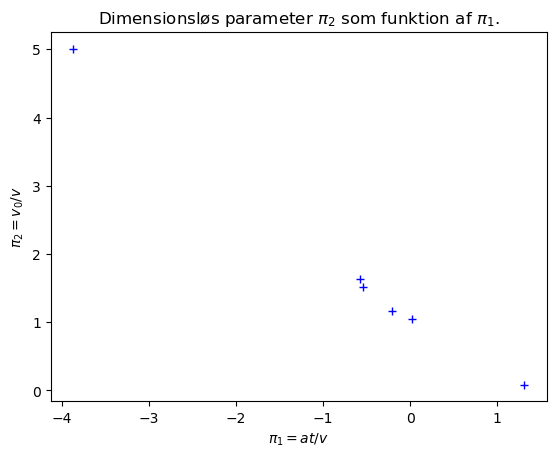

In [27]:
import matplotlib.pyplot as plt
pi_1 = a * t / v
pi_2 = v0 / v
plt.figure()
plt.plot(pi_1,pi_2,'b+')
plt.xlabel('$\pi_1=at/v$')
plt.ylabel('$\pi_2=v_0/v$')
plt.title('Dimensionsløs parameter $\pi_2$ som funktion af $\pi_1$.')
plt.show()

Da datapunkterne ser ud til at ligge på en ret linje laver vi en regressionsanalyse med modellen $\pi_2=a+b\pi_1$. 

Et hurtigt blik viser at der er data omkring (0,0) og hvis man går til det næste data punkt til højre går man lidt over en til højre og en ned, man kunne spekulere på om regressionslinjens skæringspunkt er 1 og hældningen er -1. Vi plotter den nedenfor, og det ser tilforladeligt ud. 

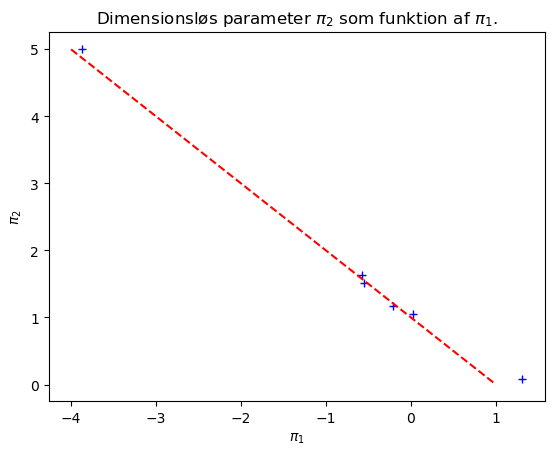

In [28]:
plt.figure()
plt.plot(pi_1,pi_2,'b+')
plt.xlabel('$\pi_1$')
plt.ylabel('$\pi_2$')
plt.plot([-4,1],[5,0],'r--')
plt.title('Dimensionsløs parameter $\pi_2$ som funktion af $\pi_1$.')
plt.show()

Vi laver regressionsanalysen med *curve_fit* metoden.
Metoden returnerer parametrene og en covariansmatrix. 
Kvadratroden af diagonalelementerne er lig med usikkerheden på parametrene.
Vi skrive begge ud. 

In [29]:
from scipy.optimize import curve_fit
def f(t,a,b):
    return a+b*t
param,cov = curve_fit(f,pi_1,pi_2)
display(param)
display(np.sqrt(np.diag(cov)))

array([ 1.11438726, -0.97618071])

array([0.07615459, 0.04473857])

Vi undersøger hvor mange standardafvigelser vi er fra 1 og -1?

Vi er under to standardafvigelser fra værdierne så det ser ud til at være et fornuftigt valg. 

In [30]:
import uncertainties as unc
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
print(A)
print(A.std_score(1.0))
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
print(B)
print(B.std_score(-1.0))

1.11+/-0.08
-1.502040337351211
-0.98+/-0.04
-0.5324105074056115


Vi plotter regressionslinjen med data, og det ser meget fint ud.

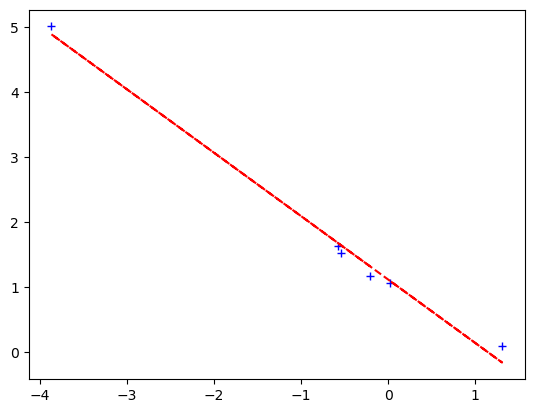

In [ ]:
plt.plot(pi_1,pi_2,'b+')
plt.plot(pi_1,f(pi_1,*param),'r--')
plt.show()

Vi får skæringen med anden aksen til at være $a=1.11\pm 0.08$.

Vi får at hældningen er $b=-0.97\pm 0.04$.

Vi gætter at $a=1$ og $b=-1$.

Indsat i modellen får vi $\pi_2=1-\pi_1$ og indsættes definitionen af de dimensionsløse parametre $\pi_1=a\cdot t/v$ og $\pi_2=v_0/v$.

Det giver $a\cdot t/v=1-v_0/v$.

Isoleres starthastigheden, $v_0$ ender vi med modellen

>$v_0=-a\cdot t+v$

Nedenfor laver vi den sidste beregning med *sympy* pakken.

In [32]:
import sympy as sp
v,v0,a,t = sp.symbols('v,v0,a,t')
expr =sp.Eq(v0/v,1-a*t/v)
display(expr)
expr = sp.Eq(v0,sp.solve(expr,v0)[0])
display(expr)

Eq(v0/v, -a*t/v + 1)

Eq(v0, -a*t + v)

Nedenfor viser vi den endelige model med data.

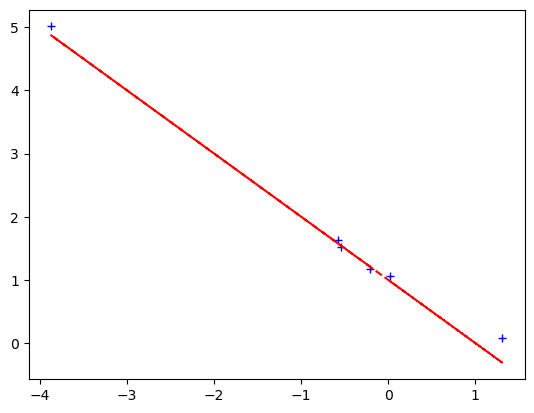

In [33]:
plt.plot(pi_1,pi_2,'b+')
plt.plot(pi_1,f(pi_1,1,-1),'r--')
plt.show()

Endelig plotter vi lige datapunkterne med usikkerheder, igen ser det fint ud.

0.19307170977312402


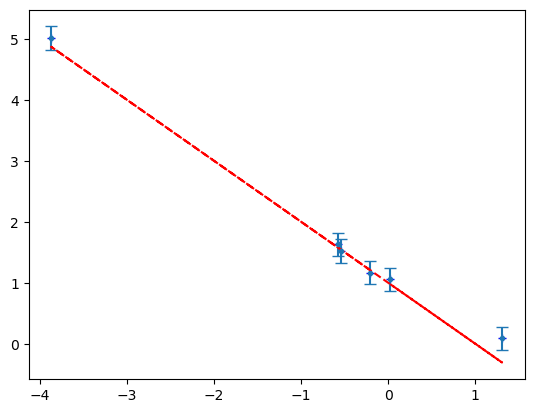

In [34]:
dy = np.sqrt(sum((pi_2-f(pi_1,1,-1))**2)/(np.size(pi_1)-1))
print(dy)
plt.plot(pi_1,pi_2,'b+')
plt.errorbar(pi_1,pi_2,yerr=dy+0*pi_1,fmt='.',capsize=4)
plt.plot(pi_1,f(pi_1,1,-1),'r--')
plt.show()

####  Opgave 3 - Flyvetur gennem Jordens indre

Vi forestiller os at der er boret en tunnel gennem Jorden, startende ved  nordpolen og sluttende ved sydpolen.
Vi slipper et legeme fra hvile lige over tunnellens åbning.
Legemet vil nu falde hele vejen gennem tunnellen og komme tilbage igen.
Hele turen tager tiden, $T$.
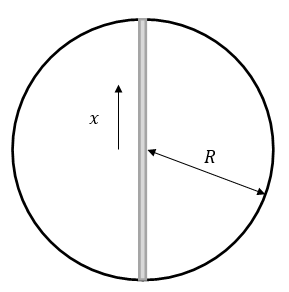

Vi ønsker at undersøge hvordan tiden for turen, $T$, afhænger af Jordens masse, $M$, Jordens radius, $R$ samt
gravitationskonstanten, $G$, dvs. at vi søger modellen

>$T = f(M,R,G)$

Graviationskonstanten har dimensionen, $[G]=\text{ M}^{-1}\text{L}^3\text{T}^{-2}$.

>a) Bestem naturlige skalaer for masse, længde og tid.

>b) Bestem modellen. (Der vil indgå en ukendt konstant.)

Jordens radius er $R=6370\text{ km}$, Jordens masse er $M=5.97\cdot 10^{24}\text{ kg}$
og gravitationskonstanten er $G=6.674\cdot 10^{-11}\text{ kg}^{-1}\text{m}^3\text{s}^{-2}$.
>c) Bestem et overslag for flyvetiden ved at sætte den ukendte konstant til $1$.

#### Løsning

>a)

Ved inspektion ses at en naturlig masseskala er $M$ og en naturlig længdeskala er $R$.

$$\mu=M$$
$$\lambda=R$$

For tiden kan vi tage udgangspunkt i $G$ der er den eneste uafhængige variabel der har tidsdimension i dens dimensionen.
Herefter vil vi gange og dividere med forskellige størrelser for at nærme os en tidsdimension.

| Udtryk    | Dimension | Kommentar |
| -------- | ------- | --|
| $G$  |   $\text{ M}^{-1}\text{L}^3\text{T}^{-2}$  | Tag reciprok for at få positiv tidsdimension|
| $\frac{1}{G}$  |   $\text{ M}^{1}\text{L}^{-3}\text{T}^{2}$  | Gang med $R^3$ for at fjerne længdedimension|
| $\frac{R^3}{G}$  |   $\text{ M}^{1}\text{L}^{0}\text{T}^{2}$  | Divider med $M$ for at fjerne massedimension|
| $\frac{R^3}{GM}$  |   $\text{ M}^{0}\text{L}^{0}\text{T}^{2}$  | Tag kvadratrod for at få tidsdimension |
| $\sqrt{\frac{R^3}{GM}}$  |   $\text{ M}^{0}\text{L}^{0}\text{T}^{1}$  | Dette er en naturlig tidsskala |

$$\tau = \sqrt{\frac{R^3}{GM}}$$

>b)

Modellen er

$T=f(M,R,G)$

Vi indsætter de naturlige skalaer

$\frac{T}{\tau}=f(\frac{M}{\mu},\frac{R}{\lambda},\frac{G}{\mu^{-1}\lambda^3\tau^{-2}})$

og indsætter værdierne for de naturlige skalaer

$\frac{T}{\sqrt{\frac{R^3}{GM}}}=f\left((\frac{M}{M},\frac{R}{R},\frac{G}{M^{-1}R^3\sqrt{\frac{R^3}{GM}}^{-2}}\right)$

$\frac{T}{\sqrt{\frac{R^3}{GM}}}=f\left(1,1,1\right)=k$

$T=k \sqrt{\frac{R^3}{GM}}$

>c) 

Indsættelse af værdier (se nedenfor) giver $T = 805.4\text{ s}$ eller $T = 13.42\text{ min}$.

In [4]:
import numpy as np
M = 5.97e24
R = 6370.e3
G = 6.674e-11
T = np.sqrt(R**3 / G / M)
print('T = {:4.1f} s'.format(T))
print('T = {:4.2f} min'.format(T/60))

T = 805.4 s
T = 13.42 min
